In [8]:
from typing import TypedDict,Literal

class PortfolioState(TypedDict):
    amount_usd:float
    total_usd:float
    target_currency:Literal["INR","EUR"]
    total:float

In [12]:
def calc_total(state:PortfolioState) -> PortfolioState:
    state["total_usd"] = state["amount_usd"] * 1.08
    return state
def convert_to_inr(state:PortfolioState) -> PortfolioState:
    state["total"] = state["total_usd"] * 95
    return state
def convert_to_eur(state:PortfolioState) -> PortfolioState:
    state["total"] = state["total_usd"] * 108
    return state
def choose_conversion(state:PortfolioState) -> str:
    return state["target_currency"]


In [13]:
from langgraph.graph import StateGraph,START,END

builder = StateGraph(PortfolioState)

builder.add_node("calc_total_node",calc_total)
builder.add_node("convert_to_inr_node",convert_to_inr)
builder.add_node("convert_to_eur_node",convert_to_eur)

builder.add_edge(START,"calc_total_node")
builder.add_conditional_edges(
    "calc_total_node",
    choose_conversion,
    {
        "INR":"convert_to_inr_node",
        "EUR":"convert_to_eur_node",
    }
)
builder.add_edge(["convert_to_inr_node","convert_to_eur_node"],END)
graph = builder.compile()

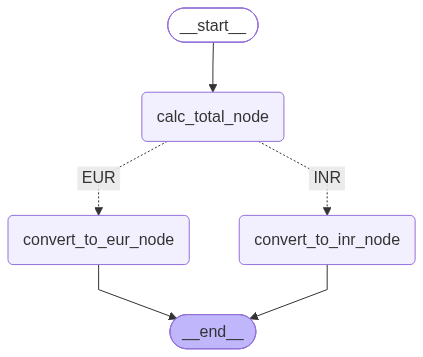

In [14]:
from IPython.display import Image,display

display(Image(graph.get_graph().draw_mermaid_png()))

In [15]:
graph.invoke({"amount_usd":100,"target_currency":"INR"})

{'amount_usd': 100,
 'total_usd': 108.0,
 'target_currency': 'INR',
 'total': 10260.0}

In [16]:
graph.invoke({"amount_usd":100,"target_currency":"EUR"})

{'amount_usd': 100,
 'total_usd': 108.0,
 'target_currency': 'EUR',
 'total': 11664.0}